Part 3 of Hyperparameter tuning - Ensemble learning

From the earlier 2 parts:

From Part 1 (tuning on pr-auc)
* Best Performing Model is LightGBM (performed the best on the holdout dataset (best PR_AUC, ROC_AUC, Precision, F1)), performance on Recall is onl second to CatBoost
* Best Parameters for LightGBM:
`{'model__scale_pos_weight': 3.0, 'model__num_leaves': 31, 'model__n_estimators': 500, 'model__min_child_samples': 50, 'model__max_depth': 20, 'model__learning_rate': 0.1}`

From Part 2 (tuning on log_loss)
* Best performing model is LightGBM (lowest holdout log loss, highest ROC-AUC, PR-AUC)
* Best parameters:
`{'model__scale_pos_weight': 3.0, 'model__num_leaves': 15, 'model__n_estimators': 500, 'model__min_child_samples': 20, 'model__max_depth': 10, 'model__learning_rate': 0.03}`

Holdout performance:
| model | holdout_log_loss | holdout_brier_score | holdout_ROC_AUC | holdout_PR_AUC | holdout_precision | holdout_recall | holdout_F1 | mean_p_illicit | median_p_illicit | max_p_illicit |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| LightGBM tuned on log loss | 0.018837 | 0.004884 | 0.999085 | 0.995396 | 0.981919 | 0.968450 | 0.975138 | 0.118534 | 1.456031e-04 | 0.999905 |
| LightGBM tuned on PR-AUC | 0.029987 | 0.004445 | 0.998877 | 0.995665 | 0.990127 | 0.962963 | 0.976356 | 0.113323 | 4.787395e-10 | 1.000000 |

* however, looking at the rows where pr_auc and log_loss `p_illicit` are greatly different, there are rows where the log_loss tuned model performed worse (giving high p_illicit to non-illcit rows), which pr_auc tuned model avoided (correctly giving a low p_illicit to non-illciit rows)

Thus, this is my attempt at using Ensemble learning to improve the outcome
----
* i am re-suing the same train_ids to tune and select the best ensemble weight (train_test_split has consistent random_state = 100)
* the test_ids will be used to compare with 100% pr_auc, and 100% log_loss tuned models

----
Results:

| index | model | holdout_log_loss | holdout_brier_score | holdout_ROC_AUC | holdout_PR_AUC | holdout_precision | holdout_recall | holdout_F1 |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **0** | Ensemble (0.70 log-loss / 0.30 PR-AUC) | 0.017136 | 0.004390 | 0.999164 | 0.995899 | 0.990169 | 0.967078 | 0.978487 |
| **1** | 100% log-loss tuned | 0.019000 | 0.005048 | 0.999108 | 0.995487 | 0.977809 | 0.967078 | 0.972414 |
| **2** | 100% PR-AUC tuned | 0.027243 | 0.004285 | 0.998921 | 0.996113 | 0.992958 | 0.967078 | 0.979847 |

* I pick the ensemble with the best weights (0.70 log-loss / 0.30 PR-AUC), as iit has the best log-loss and ROC-AUC.

In [20]:
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.base import clone

from sklearn.model_selection import train_test_split,  StratifiedKFold
from sklearn.model_selection import cross_val_predict

from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
)

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

In [2]:
#as both the best pr-auc and log-loss model is LigthGBM, only need train_raw

train_raw = pd.read_csv("train_raw_node_info.csv", header = 0)

In [3]:
# Get numeric predictors in the same txId order as the split.
# time_step is included as a predictor; txId, index, and label are excluded.
def get_X_for_ids(df, ids):
    indexed = df.set_index("txId", drop=False)
    aligned = indexed.loc[list(ids)]

    excluded = {"txId", "index", "label"}
    feature_columns = [
        c for c in aligned.select_dtypes(include=np.number).columns
        if c not in excluded
    ]
    return aligned[feature_columns]

In [4]:
known = train_raw.loc[train_raw["label"].notna()].copy()
known["label"] = known["label"].astype(int)

strata = (
    known["time_step"].astype(str)
    + "_label_"
    + known["label"].astype(str)
)

stratum_counts = strata.value_counts()
if (stratum_counts < 2).any():
    raise ValueError("At least one time_step/label group has fewer than 2 rows.")

train_ids, test_ids = train_test_split(
    known["txId"],
    test_size=0.20,
    random_state=100,
    stratify=strata,
)

In [5]:
# Fixed parameters selected previously
pr_auc_params = {
    "scale_pos_weight": 3.0,
    "num_leaves": 31,
    "n_estimators": 500,
    "min_child_samples": 50,
    "max_depth": 20,
    "learning_rate": 0.1,
}

log_loss_params = {
    "scale_pos_weight": 3.0,
    "num_leaves": 15,
    "n_estimators": 500,
    "min_child_samples": 20,
    "max_depth": 10,
    "learning_rate": 0.03,
}

In [6]:
def create_lgbm_pipeline(params):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LGBMClassifier(
            objective="binary",
            random_state=100,
            verbosity=-1,
            n_jobs=-1,
            **params,
        )),
    ])

In [7]:
ensemble_weights = [
    0.0,   # 100% PR-AUC-tuned model
    0.25,  # 25% log-loss, 75% PR-AUC
    0.50,  # 50/50
    0.75,  # 75% log-loss, 25% PR-AUC
    1.0,   # 100% log-loss-tuned model
]


Ensemble weight tuning:
* use shuffled stratified out-of-fold predictions on train_ids (ok for retrospective labelling)
* test_ids is the holdout ids only kept for the final comparison with 100% pr-auc and 100% log-loss
* set primary tuning metric to be log-loss

In [8]:
def evaluate_holdout(name, p):
    hard = (p >= 0.5).astype(int)
    return {
        "model": name,
        "holdout_log_loss": log_loss(y_holdout, p),
        "holdout_brier_score": brier_score_loss(y_holdout, p),
        "holdout_ROC_AUC": roc_auc_score(y_holdout, p),
        "holdout_PR_AUC": average_precision_score(y_holdout, p),
        "holdout_precision": precision_score(y_holdout, hard, zero_division=0),
        "holdout_recall": recall_score(y_holdout, hard, zero_division=0),
        "holdout_F1": f1_score(y_holdout, hard, zero_division=0),
    }

In [9]:
known_by_id = known.set_index("txId", drop=False)
train_id_list = list(train_ids) #for cross-validation
test_id_list = list(test_ids) #at the end, the holdout

# Recreate matrices using the same txId ordering as the labels.
X_dev = get_X_for_ids(train_raw, train_id_list)
X_holdout = get_X_for_ids(train_raw, test_id_list)
y_dev = known_by_id.loc[train_id_list, "label"].astype(int)
y_holdout = known_by_id.loc[test_id_list, "label"].astype(int)


In [10]:
# Same CV strata design
cv_strata = (
    known_by_id.loc[train_id_list, "time_step"].astype(str)
    + "_label_"
    + y_dev.astype(str)
)
if cv_strata.value_counts().min() >= 3:
    stratify_values = cv_strata
else:
    stratify_values = y_dev
    print("Using label-only stratification for CV.")
n_splits_ensemble = min(3, int(stratify_values.value_counts().min()))
if n_splits_ensemble < 2:
    raise ValueError("Not enough examples for stratified CV.")
cv_ensemble = list(StratifiedKFold(
    n_splits=n_splits_ensemble, shuffle=True, random_state=100
).split(np.zeros(len(y_dev)), stratify_values))


In [11]:
pr_auc_model = create_lgbm_pipeline(pr_auc_params)
log_loss_model = create_lgbm_pipeline(log_loss_params)

# Out-of-fold probabilities prevent a row being scored by a model trained on it.
p_pr_auc_oof = cross_val_predict(
    clone(pr_auc_model), X_dev, y_dev, cv=cv_ensemble,
    method="predict_proba", n_jobs=1
)[:, 1]
p_log_loss_oof = cross_val_predict(
    clone(log_loss_model), X_dev, y_dev, cv=cv_ensemble,
    method="predict_proba", n_jobs=1
)[:, 1]

In [12]:
# weight_log_loss is the contribution of the log-loss-tuned model.
weight_grid = np.round(np.arange(0.0, 1.01, 0.05), 2)
weight_results = []
for weight_log_loss in weight_grid:
    weight_pr_auc = 1.0 - weight_log_loss
    p_oof = weight_log_loss * p_log_loss_oof + weight_pr_auc * p_pr_auc_oof
    weight_results.append({
        "weight_log_loss": weight_log_loss,
        "weight_pr_auc": weight_pr_auc,
        "oof_log_loss": log_loss(y_dev, p_oof),
        "oof_brier_score": brier_score_loss(y_dev, p_oof),
        "oof_ROC_AUC": roc_auc_score(y_dev, p_oof),
        "oof_PR_AUC": average_precision_score(y_dev, p_oof),
    })

weight_results_df = (pd.DataFrame(weight_results)
    .sort_values(["oof_log_loss", "oof_ROC_AUC"], ascending=[True, False])
    .reset_index(drop=True))
display(weight_results_df)
best_weight_log_loss = weight_results_df.loc[0, "weight_log_loss"]
best_weight_pr_auc = 1.0 - best_weight_log_loss
print("Selected log-loss weight:", best_weight_log_loss)
print("Selected PR-AUC weight:", best_weight_pr_auc)

,weight_log_loss,weight_pr_auc,oof_log_loss,oof_brier_score,oof_ROC_AUC,oof_PR_AUC
0,0.70,0.30,0.021539,0.005137,0.998521,0.993256
1,0.75,0.25,0.021542,0.005158,0.998519,0.993240
2,0.65,0.35,0.021563,0.005122,0.998523,0.993268
3,0.80,0.20,0.021571,0.005185,0.998517,0.993224
4,0.60,0.40,0.021618,0.005114,0.998524,0.993281
5,0.85,0.15,0.021625,0.005219,0.998514,0.993206
6,0.90,0.10,0.021703,0.005258,0.998511,0.993183
7,0.55,0.45,0.021707,0.005111,0.998526,0.993291
8,0.95,0.05,0.021805,0.005303,0.998508,0.993159
9,0.50,0.50,0.021835,0.005114,0.998528,0.993303


Selected log-loss weight: 0.7
Selected PR-AUC weight: 0.30000000000000004


Part 2: Evaluate test_ids (holdout) performance

In [13]:
# Fit the fixed component models on all train_ids and evaluate test_ids once.
final_pr_auc_model = create_lgbm_pipeline(pr_auc_params).fit(X_dev, y_dev)
final_log_loss_model = create_lgbm_pipeline(log_loss_params).fit(X_dev, y_dev)
p_pr_auc_holdout = final_pr_auc_model.predict_proba(X_holdout)[:, 1]
p_log_loss_holdout = final_log_loss_model.predict_proba(X_holdout)[:, 1]
p_ensemble_holdout = (best_weight_log_loss * p_log_loss_holdout
                      + best_weight_pr_auc * p_pr_auc_holdout)

In [14]:
ensemble_holdout_results = pd.DataFrame([
    evaluate_holdout("100% PR-AUC tuned", p_pr_auc_holdout),
    evaluate_holdout("100% log-loss tuned", p_log_loss_holdout),
    evaluate_holdout(
        f"Ensemble ({best_weight_log_loss:.2f} log-loss / {best_weight_pr_auc:.2f} PR-AUC)",
        p_ensemble_holdout,
    ),
]).sort_values("holdout_log_loss").reset_index(drop=True)
display(ensemble_holdout_results)

,model,holdout_log_loss,holdout_brier_score,holdout_ROC_AUC,holdout_PR_AUC,holdout_precision,holdout_recall,holdout_F1
0,Ensemble (0.70 log-loss / 0.30 PR-AUC),0.017136,0.004390,0.999164,0.995899,0.990169,0.967078,0.978487
1,100% log-loss tuned,0.019000,0.005048,0.999108,0.995487,0.977809,0.967078,0.972414
2,100% PR-AUC tuned,0.027243,0.004285,0.998921,0.996113,0.992958,0.967078,0.979847


In [15]:
oof_fold_results = []

for fold_number, (train_idx, valid_idx) in enumerate(cv_ensemble):
    fold_model = create_lgbm_pipeline(log_loss_params)

    fold_model.fit(
        X_dev.iloc[train_idx],
        y_dev.iloc[train_idx],
    )

    p_fold = fold_model.predict_proba(
        X_dev.iloc[valid_idx]
    )[:, 1]

    oof_fold_results.append({
        "fold": fold_number,
        "n_train": len(train_idx),
        "n_validation": len(valid_idx),
        "positive_rate": y_dev.iloc[valid_idx].mean(),
        "log_loss": log_loss(
            y_dev.iloc[valid_idx],
            p_fold,
        ),
        "ROC_AUC": roc_auc_score(
            y_dev.iloc[valid_idx],
            p_fold,
        ),
        "PR_AUC": average_precision_score(
            y_dev.iloc[valid_idx],
            p_fold,
        ),
    })

oof_fold_results_df = pd.DataFrame(oof_fold_results)
display(oof_fold_results_df)

,fold,n_train,n_validation,positive_rate,log_loss,ROC_AUC,PR_AUC
0,0,16658,8330,0.117047,0.024334,0.997953,0.991717
1,1,16659,8329,0.116340,0.019742,0.998847,0.994549
2,2,16659,8329,0.116581,0.021716,0.998879,0.993389


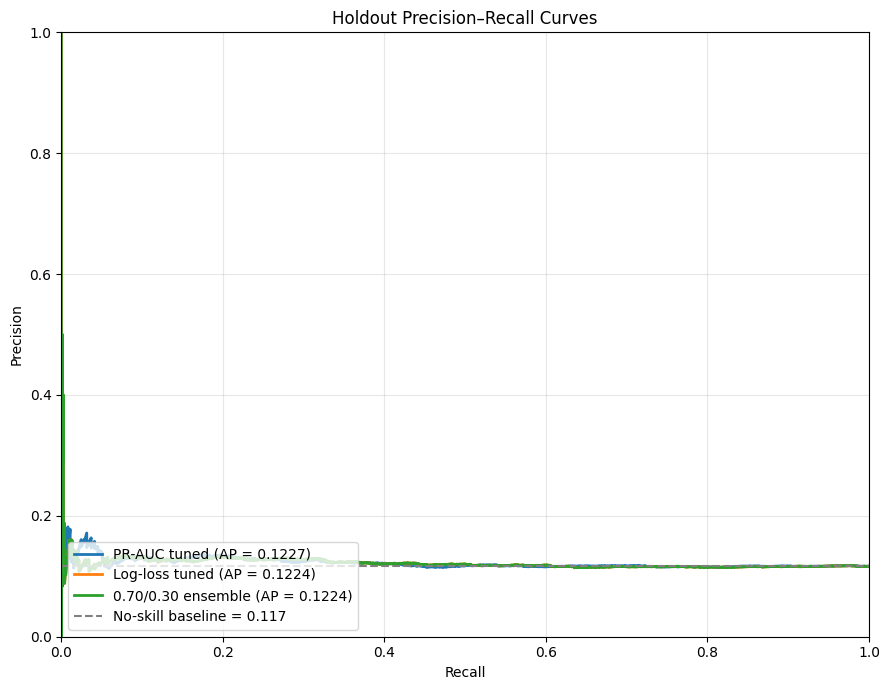

In [21]:
models_to_plot = {
    "PR-AUC tuned": p_pr_auc_holdout,
    "Log-loss tuned": p_log_loss_holdout,
    (f"{best_weight_log_loss:.2f}/{best_weight_pr_auc:.2f} ensemble"): p_ensemble_holdout,
}

plt.figure(figsize=(9, 7))

for model_name, probabilities in models_to_plot.items():
    precision, recall, _ = precision_recall_curve(
        y_holdout,
        probabilities,
    )

    ap = average_precision_score(
        y_holdout,
        probabilities,
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{model_name} (AP = {ap:.4f})",
    )

# No-skill baseline: holdout positive-class prevalence
holdout_prevalence = y_holdout.mean()

plt.axhline(
    y=holdout_prevalence,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"No-skill baseline = {holdout_prevalence:.3f}",
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Holdout Precision–Recall Curves")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()